In [1]:
import sys
print(sys.executable)

import ipywidgets
print(ipywidgets.__version__)

C:\Users\gab\anaconda3\envs\bitcoin_ml\python.exe
8.1.9


In [2]:
import ipywidgets as widgets
widgets.IntSlider()

IntSlider(value=0)

In [3]:
#Importing Libraries
import matplotlib
import ipympl
import ipywidgets

print("Matplotlib:", matplotlib.__version__)
print("ipympl:", ipympl.__version__)
print("ipywidgets:", ipywidgets.__version__)

Matplotlib: 3.11.0
ipympl: 0.10.0
ipywidgets: 8.1.9


In [4]:
import sys
import subprocess

python = sys.executable

result = subprocess.run(
    [python, "-m", "pip", "show", "jupyterlab_widgets"],
    capture_output=True,
    text=True
)

print(result.stdout if result.stdout else result.stderr)

Name: jupyterlab_widgets
Version: 3.0.17
Summary: Jupyter interactive widgets for JupyterLab
Home-page: https://github.com/jupyter-widgets/ipywidgets
Author: 
Author-email: Jupyter Development Team <jupyter@googlegroups.com>
License: Copyright (c) 2015 Project Jupyter Contributors
All rights reserved.

Redistribution and use in source and binary forms, with or without
modification, are permitted provided that the following conditions are met:

1. Redistributions of source code must retain the above copyright notice, this
   list of conditions and the following disclaimer.

2. Redistributions in binary form must reproduce the above copyright notice,
   this list of conditions and the following disclaimer in the documentation
   and/or other materials provided with the distribution.

3. Neither the name of the copyright holder nor the names of its
   contributors may be used to endorse or promote products derived from
   this software without specific prior written permission.

THIS SOFT

In [5]:
import ipywidgets as widgets
from IPython.display import display

slider = widgets.IntSlider(
    value=5,
    min=0,
    max=10,
    description="Test:"
)

display(slider)


IntSlider(value=5, description='Test:', max=10)

In [6]:
from IPython.display import display, HTML

display(HTML("""
<script>
console.log("Open the browser developer console with F12,
then check the Console tab for widget errors.");
</script>
"""))

In [7]:
# In this Project I used Matplotlibwidgets. I encountered some issued with the loading of the widgets.
%matplotlib widget

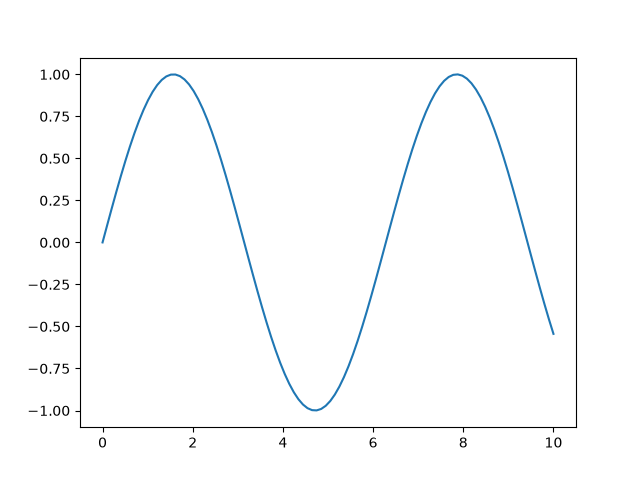

In [8]:
import matplotlib.pyplot as plt
import numpy as np

x = np.linspace(0, 10, 100)

plt.figure()
plt.plot(x, np.sin(x))
plt.show()

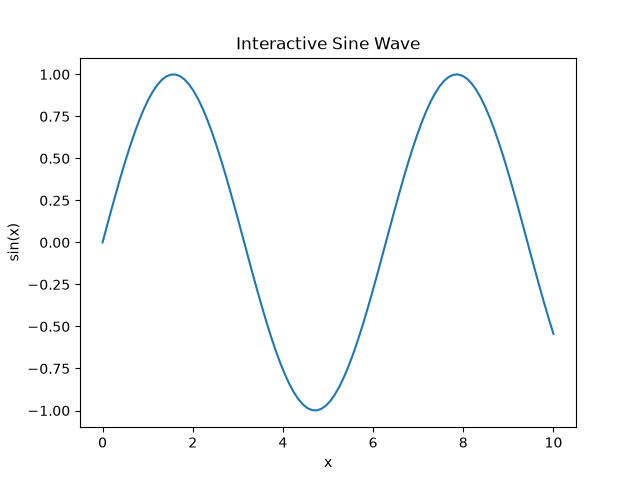

In [9]:
import matplotlib.pyplot as plt
import numpy as np

x = np.linspace(0, 10, 100)
y = np.sin(x)

fig, ax = plt.subplots()

ax.plot(x, y)

ax.set_title("Interactive Sine Wave")
ax.set_xlabel("x")
ax.set_ylabel("sin(x)")

plt.show()

height=887,width=1774


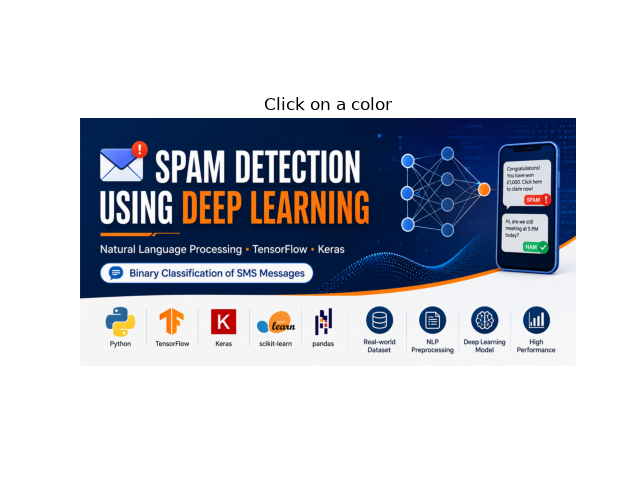

In [13]:
%matplotlib widget
import cv2
import numpy as np
import matplotlib.pyplot as plt
img=cv2.imread('banner.png.png')
img
h,w=img.shape[:2]
print("height={},width={}".format(h,w))
# Load image
image = img

# Check image
if image is None:
    print("Image could not be loaded")
else:

    # Convert BGR to RGB for Matplotlib
    image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    # Convert BGR to HSV for OpenCV processing
    hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)

    # Store clicked HSV values
    points = []

    # Create figure
    fig, ax = plt.subplots()

    # Display image
    ax.imshow(image_rgb)
    ax.set_title("Click on a color")
    ax.axis("off")

    # Mouse click function
    def onclick(event):

        # Make sure click happened inside image
        if event.xdata is not None and event.ydata is not None:

            # Matplotlib gives x,y coordinates
            x = int(event.xdata)
            y = int(event.ydata)

            # Get BGR and HSV values
            bgr_value = image[y, x]
            hsv_value = hsv[y, x]

            # Store HSV
            points.append(hsv_value)

            print("Position:", (x, y))
            print("BGR:", bgr_value)
            print("HSV:", hsv_value)
            print("Collected:", len(points))
            print("------------------------")

    # Connect mouse click to function
    cid = fig.canvas.mpl_connect(
        "button_press_event",
        onclick
    )

    plt.show()

In [14]:
np.array(points)

array([[ 14, 252, 255],
       [  5, 229, 248],
       [ 23, 210, 254],
       [ 23, 207, 254],
       [ 23, 211, 253],
       [ 13, 252, 253],
       [ 15, 210, 250],
       [ 14, 220, 254],
       [ 13, 239, 254]], dtype=uint8)

In [15]:
points = np.array(points)

print("Minimum HSV:", points.min(axis=0))
print("Maximum HSV:", points.max(axis=0))

Minimum HSV: [  5 207 248]
Maximum HSV: [ 23 252 255]


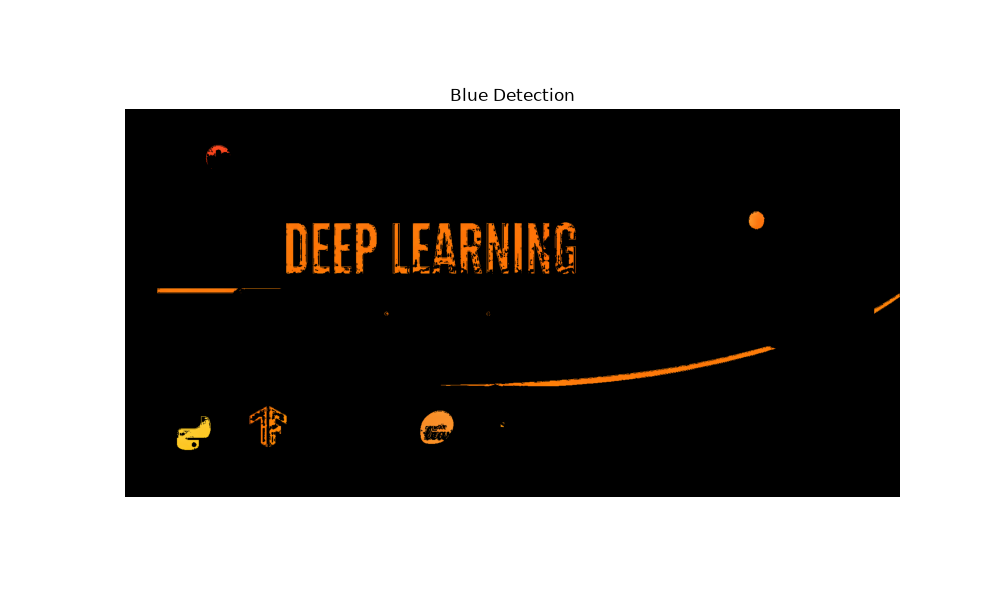

In [16]:
mask = cv2.inRange(hsv,  points.min(axis=0), points.max(axis=0))
result = cv2.bitwise_and(img, img, mask=mask)
plt.figure(figsize=(10, 6))

plt.imshow(
    cv2.cvtColor(result, cv2.COLOR_BGR2RGB)
)

plt.title("Blue Detection")
plt.axis("off")

plt.show()


In [17]:
contours, hierarchy = cv2.findContours(
    mask,
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_SIMPLE
)

print("Number of contours:", len(contours))

Number of contours: 142


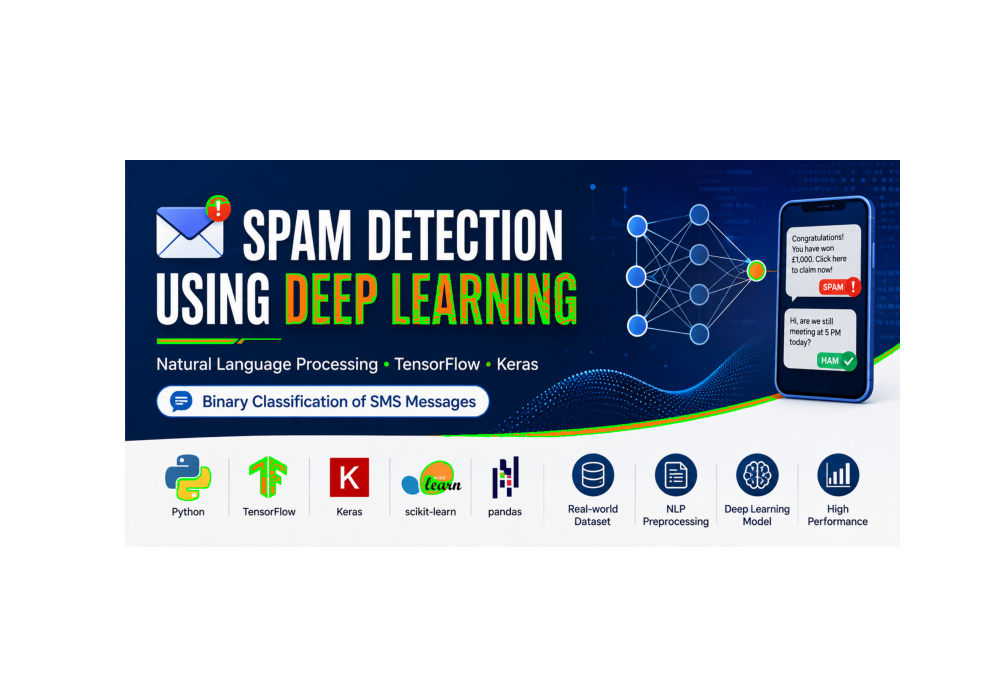

In [18]:
contour_image = img.copy()

cv2.drawContours(
    contour_image,
    contours,
    -1,
    (0, 255, 0),
    2
)

plt.figure(figsize=(10, 7))

plt.imshow(
    cv2.cvtColor(contour_image, cv2.COLOR_BGR2RGB)
)

plt.axis("off")
plt.show()

In [ ]:
points

In [ ]:
for i,cont in enumerate(contours):
    Area=cv2.contourArea(cont)
    if Area>500:
        contr=cv2.drawContours(contour_image,contours,-1,(0,255,0),3)
        plt.imshow(cv2.cvtColor(contr,cv2.COLOR_BGR2RGB))
        plt.axis('off')
        plt.show()
    else:
        print('Area is too small')

In [ ]:
max_c=max(contours,key=cv2.contourArea)
max_c

In [ ]:
cv2.contourArea(max_c)

In [ ]:
x,y,w,h=cv2.boundingRect(max_c)
img4= img.copy()
res=cv2.rectangle(img4,(x,y),(x+w,y+h),(225,225,225),5)
plt.imshow(cv2.cvtColor(res,cv2.COLOR_BGR2RGB))
plt.show()

In [ ]:
perimeter=cv2.arcLength(max_c,True)
perimeter

In [ ]:
center=cv2.moments(max_c)


In [ ]:
M=cv2.moments(max_c)
if M["m00"]!=0:
    cx=int(M["m10"]/M["m00"])
    cy=int(M["m01"]/M["m00"])
    print('(cx,cy):',cx,cy)
else:
    print("cont")


In [ ]:
img5=img.copy()
center=cv2.circle(img5,(cx,cy),7,(0,0,225),-1)
plt.imshow(cv2.cvtColor(center,cv2.COLOR_BGR2RGB))
plt.show()

In [ ]:
for factor in [0.005,0.02,0.01,0.05]:
    epsilon=factor*perimeter
    poly=cv2.approxPolyDP(max_c,epsilon,True)
    print('factor:',factor),print('sides:',len(poly))